# Miniproyecto 3 — Clasificador de tornillería


## 1. Librerías y configuración

In [18]:
import os, json, random, shutil, zipfile, time
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [19]:
# ===================== CONFIGURACIÓN =====================
# Nombres EXACTOS de las carpetas (sin tildes ni espacios).
CLASES = ["tuerca", "arandela", "tornillo", "tornillo_largo", "perno_hex"]

# Ángulos del Servo 1 según tu plan (tobogán -> caja de cada clase).
ANGULOS = {"tuerca": 20, "arandela": 55, "tornillo": 90, "tornillo_largo": 125, "perno_hex": 160}

HEIGHT, WIDTH = 224, 224     # tamaño de entrada de MobileNetV2
BATCH_SIZE = 32              # dataset pequeño: 32 funciona mejor que 64
EPOCHS = 30                  # máximo; EarlyStopping corta antes si ya no mejora
LEARNING_RATE = 1e-3
FRAC_VAL, FRAC_TEST = 0.15, 0.15   # reparto de las fotos PROPIAS (el resto va a train)
FINE_TUNE = True            # True para afinar las últimas capas

NOMBRE_MODELO = "modelo_tornillos"

## 2. Subir y organizar el dataset


In [20]:
from google.colab import files
subido = files.upload()   # dataset_tornilleria.zip
ZIP = list(subido.keys())[0]

RAW = "/content/raw"
shutil.rmtree(RAW, ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall(RAW)

def buscar_carpeta(nombre):
    for raiz, dirs, _ in os.walk(RAW):
        if nombre in dirs:
            return os.path.join(raiz, nombre)
    return None

PROPIO = buscar_carpeta("propio")
PUBLICO = buscar_carpeta("publico")
assert PROPIO, "No encontré la carpeta 'propio' dentro del zip."
print("propio :", PROPIO)
print("publico:", PUBLICO if PUBLICO else "(no incluido)")

Saving dataset_tornilleria.zip to dataset_tornilleria (1).zip
propio : /content/raw/dataset_tornilleria/propio
publico: /content/raw/dataset_tornilleria/publico


In [21]:
EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
DATA = "/content/dataset"
shutil.rmtree(DATA, ignore_errors=True)
for s in ["train", "val", "test"]:
    for c in CLASES:
        os.makedirs(f"{DATA}/{s}/{c}", exist_ok=True)

def listar(base, clase):
    carpeta = os.path.join(base, clase)
    if not os.path.isdir(carpeta):
        return []
    return sorted(f for f in os.listdir(carpeta) if f.lower().endswith(EXT))

for clase in CLASES:
    imgs = listar(PROPIO, clase)
    assert len(imgs) >= 10, f"Clase '{clase}': solo {len(imgs)} fotos propias. Revisa el nombre de la carpeta."
    fijas_test = [f for f in imgs if f.startswith("test_")]
    resto = [f for f in imgs if not f.startswith("test_")]
    random.shuffle(resto)
    n_test = max(1, round(len(imgs) * FRAC_TEST)) - len(fijas_test)
    n_test = max(0, n_test)
    n_val = max(1, round(len(imgs) * FRAC_VAL))
    test_f = fijas_test + resto[:n_test]
    val_f = resto[n_test:n_test + n_val]
    train_f = resto[n_test + n_val:]
    for lista, s in [(train_f, "train"), (val_f, "val"), (test_f, "test")]:
        for f in lista:
            shutil.copy(os.path.join(PROPIO, clase, f), f"{DATA}/{s}/{clase}/{f}")
    # públicas -> solo train
    if PUBLICO:
        for f in listar(PUBLICO, clase):
            shutil.copy(os.path.join(PUBLICO, clase, f), f"{DATA}/train/{clase}/pub_{f}")

print(f"{'clase':<16}{'train':>7}{'val':>6}{'test':>6}")
for c in CLASES:
    n = [len(os.listdir(f"{DATA}/{s}/{c}")) for s in ["train", "val", "test"]]
    print(f"{c:<16}{n[0]:>7}{n[1]:>6}{n[2]:>6}")

clase             train   val  test
tuerca              316     4    10
arandela            316     4    10
tornillo            316     4    10
tornillo_largo      278     4    10
perno_hex           269     4    10


## 3. Generadores de datos y *data augmentation*
- Solo *train* lleva aumento de datos. *val* y *test* solo se normalizan (÷255), igual que en el ejemplo.
- Las piezas se ven desde arriba y pueden quedar en cualquier orientación: rotación 180° y volteos son válidos.
- `fill_mode="constant"` rellena con negro, igual que la cartulina negra.
- `classes=CLASES` fija el orden de las clases (por defecto Keras las ordena alfabéticamente y eso cambiaría los índices).

In [22]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=180,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    brightness_range=[0.7, 1.3],
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="constant", cval=0,
)
eval_datagen = ImageDataGenerator(rescale=1./255)

kw = dict(target_size=(HEIGHT, WIDTH), class_mode="categorical", classes=CLASES, batch_size=BATCH_SIZE)
train = train_datagen.flow_from_directory(f"{DATA}/train", shuffle=True, seed=SEED, **kw)
val   = eval_datagen.flow_from_directory(f"{DATA}/val", shuffle=False, **kw)
test  = eval_datagen.flow_from_directory(f"{DATA}/test", shuffle=False, **kw)   # shuffle=False: necesario para la matriz de confusión

print("Índices de clase:", train.class_indices)

Found 1495 images belonging to 5 classes.
Found 20 images belonging to 5 classes.
Found 50 images belonging to 5 classes.
Índices de clase: {'tuerca': 0, 'arandela': 1, 'tornillo': 2, 'tornillo_largo': 3, 'perno_hex': 4}


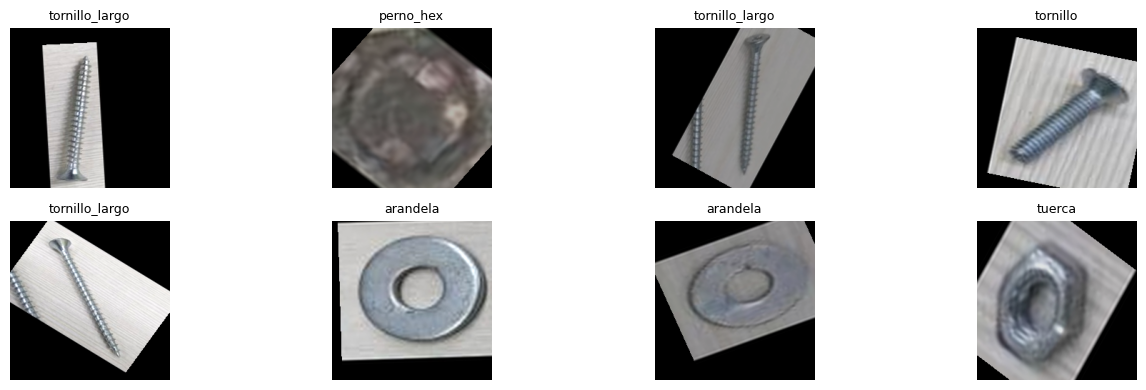

In [23]:
# Vista previa de imágenes aumentadas
x, y = next(train)
plt.figure(figsize=(14, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x[i]); plt.axis("off")
    plt.title(CLASES[np.argmax(y[i])], fontsize=9)
plt.tight_layout(); plt.show()

## 4. Modelo: MobileNetV2 + Transfer Learning
Se congela toda la parte convolucional (`trainable = False`) y solo se entrena el clasificador nuevo.
Si hay más fotos de unas clases que de otras (por ejemplo, si una clase tiene muchas más fotos públicas que otra), se calculan pesos por clase para compensar.

In [24]:
base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(HEIGHT, WIDTH, 3))
base.trainable = False   # CONGELAR el conocimiento previo

model = Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(CLASES), activation="softmax"),
])
model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

pesos = compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=train.classes)
class_weight = {i: float(w) for i, w in enumerate(pesos)}
print("Pesos por clase:", {CLASES[i]: round(w, 2) for i, w in class_weight.items()})

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Pesos por clase: {'tuerca': 0.95, 'arandela': 0.95, 'tornillo': 0.95, 'tornillo_largo': 1.08, 'perno_hex': 1.11}


## 5. Entrenamiento

In [25]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
]
history = model.fit(train, validation_data=val, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks, verbose=1)

Epoch 1/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 37s 597ms/step - accuracy: 0.8548 - loss: 0.3817 - val_accuracy: 0.5500 - val_loss: 1.1551 - learning_rate: 0.0010
Epoch 2/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 439ms/step - accuracy: 0.9605 - loss: 0.1128 - val_accuracy: 0.5000 - val_loss: 1.5396 - learning_rate: 0.0010
Epoch 3/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 457ms/step - accuracy: 0.9672 - loss: 0.0880 - val_accuracy: 0.5000 - val_loss: 1.1336 - learning_rate: 0.0010
Epoch 4/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 465ms/step - accuracy: 0.9679 - loss: 0.0772 - val_accuracy: 0.5000 - val_loss: 1.0548 - learning_rate: 0.0010
Epoch 5/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 443ms/step - accuracy: 0.9739 - loss: 0.0731 - val_accuracy: 0.6000 - val_loss: 1.0091 - learning_rate: 0.0010
Epoch 6/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 489ms/step - accuracy: 0.9746 - loss: 0.0703 - val_accuracy: 0.6000 - val_loss: 0.9011 - learning_rate: 0.0010
Epoch 7/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 459ms/step - accuracy: 0.9786 - loss: 0.

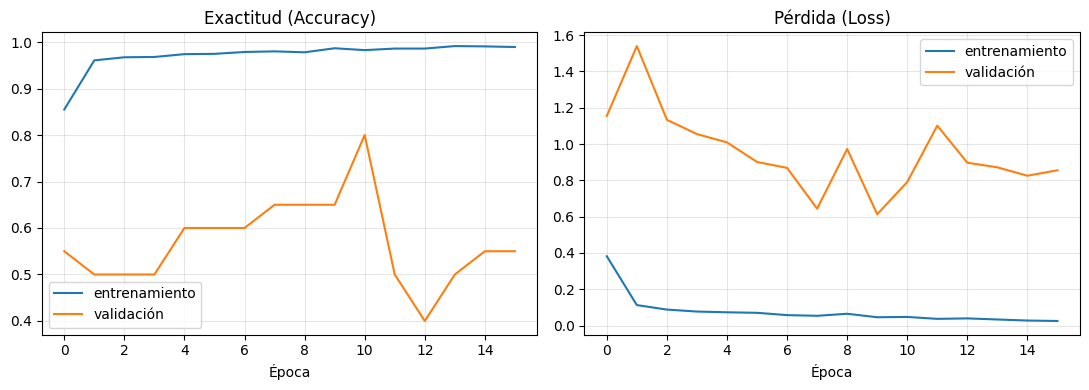

In [26]:
def graficar_curvas(h, archivo="curvas_entrenamiento.png"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["accuracy"], label="entrenamiento"); ax[0].plot(h["val_accuracy"], label="validación")
    ax[0].set_title("Exactitud (Accuracy)"); ax[0].set_xlabel("Época"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["loss"], label="entrenamiento"); ax[1].plot(h["val_loss"], label="validación")
    ax[1].set_title("Pérdida (Loss)"); ax[1].set_xlabel("Época"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(archivo, dpi=300); plt.show()

graficar_curvas(history.history)

## 6.  fino de las últimas capas
Se descongelan solo las últimas 30 capas de MobileNetV2 (las capas *BatchNormalization* se dejan congeladas) con una tasa de aprendizaje muy baja.
Dejar **todas** las capas entrenables: sería borrar el conocimiento previo.

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 50s 770ms/step - accuracy: 0.9846 - loss: 0.0379 - val_accuracy: 0.7000 - val_loss: 0.6563
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 464ms/step - accuracy: 0.9886 - loss: 0.0344 - val_accuracy: 0.7000 - val_loss: 0.7136
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 489ms/step - accuracy: 0.9880 - loss: 0.0297 - val_accuracy: 0.7500 - val_loss: 0.5472
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 484ms/step - accuracy: 0.9873 - loss: 0.0292 - val_accuracy: 0.5500 - val_loss: 0.6016
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 457ms/step - accuracy: 0.9913 - loss: 0.0267 - val_accuracy: 0.7000 - val_loss: 0.7212
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 42s 472ms/step - accuracy: 0.9920 - loss: 0.0275 - val_accuracy: 0.8000 - val_loss: 0.5505
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 471ms/step - accuracy: 0.9953 - loss: 0.0196 - val_accuracy: 0.8500 - val_loss: 0.4518
Epoch 8/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 463ms/step - accuracy: 0.9920 - loss: 0.0232 - val_accu

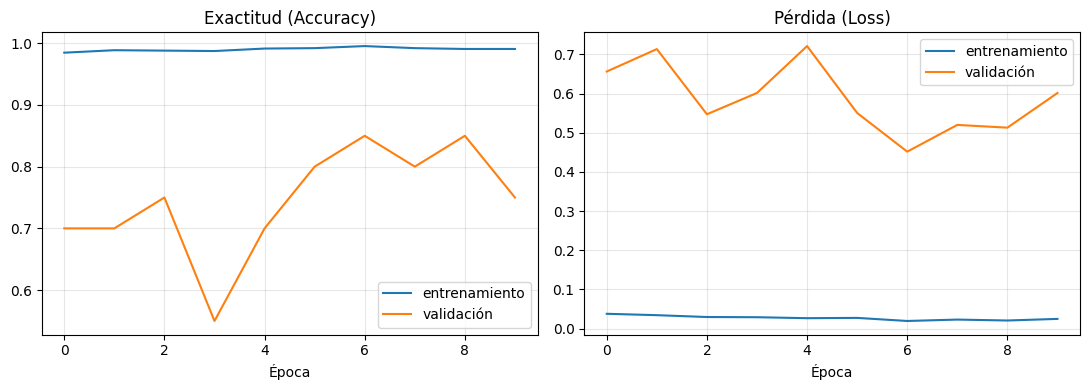

In [27]:
if FINE_TUNE:
    base.trainable = True
    for capa in base.layers[:-30]:
        capa.trainable = False
    for capa in base.layers:
        if isinstance(capa, layers.BatchNormalization):
            capa.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    history_ft = model.fit(train, validation_data=val, epochs=10,
                           class_weight=class_weight, callbacks=callbacks[:1], verbose=1)
    graficar_curvas(history_ft.history, "curvas_fine_tuning.png")
else:
    print("FINE_TUNE = False -> se omite.")

## 7. Evaluación en test: exactitud, matriz de confusión y reporte

Test -> loss: 0.3639 | accuracy: 0.8800


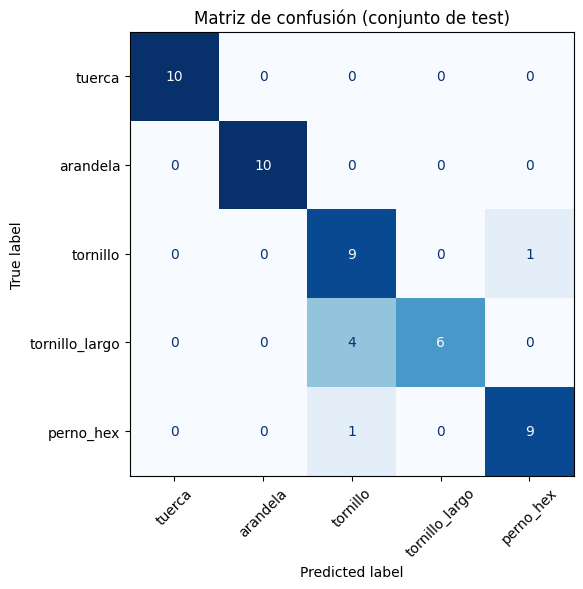

                precision    recall  f1-score   support

        tuerca      1.000     1.000     1.000        10
      arandela      1.000     1.000     1.000        10
      tornillo      0.643     0.900     0.750        10
tornillo_largo      1.000     0.600     0.750        10
     perno_hex      0.900     0.900     0.900        10

      accuracy                          0.880        50
     macro avg      0.909     0.880     0.880        50
  weighted avg      0.909     0.880     0.880        50



In [28]:
loss, acc = model.evaluate(test, verbose=0)
print(f"Test -> loss: {loss:.4f} | accuracy: {acc:.4f}")

probs = model.predict(test, verbose=0)
y_pred = np.argmax(probs, axis=1)
y_true = test.classes

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Matriz de confusión (conjunto de test)")
plt.tight_layout(); plt.savefig("matriz_confusion.png", dpi=300); plt.show()

reporte = classification_report(y_true, y_pred, target_names=CLASES, digits=3)
print(reporte)
with open("reporte_clasificacion.txt", "w") as f:
    f.write(f"Test accuracy: {acc:.4f}\nTest loss: {loss:.4f}\n\n{reporte}")

Errores: 6 de 50


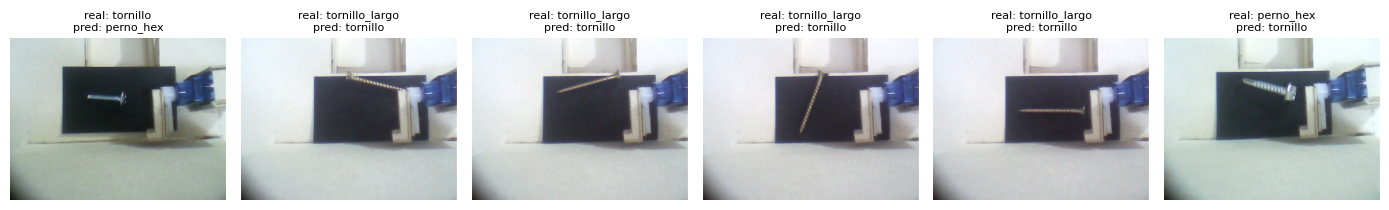

In [29]:
# Imágenes que el modelo se equivocó
errores = np.where(y_pred != y_true)[0]
print(f"Errores: {len(errores)} de {len(y_true)}")
if len(errores):
    plt.figure(figsize=(14, 3.5))
    for j, i in enumerate(errores[:8]):
        img = cv2.cvtColor(cv2.imread(test.filepaths[i]), cv2.COLOR_BGR2RGB)
        plt.subplot(1, min(8, len(errores)), j + 1)
        plt.imshow(img); plt.axis("off")
        plt.title(f"real: {CLASES[y_true[i]]}\npred: {CLASES[y_pred[i]]}", fontsize=8)
    plt.tight_layout(); plt.savefig("errores_test.png", dpi=200); plt.show()

## 8. Guardar el modelo y la configuración de clases


In [30]:
model.save(f"{NOMBRE_MODELO}.h5")
nuevo = keras.models.load_model(f"{NOMBRE_MODELO}.h5")
print("Recarga OK -> test:", nuevo.evaluate(test, verbose=0))

orden = [c for c, _ in sorted(train.class_indices.items(), key=lambda p: p[1])]
config = {
    "clases": orden,
    "angulos_servo1": {c: ANGULOS[c] for c in orden},
    "entrada": [HEIGHT, WIDTH, 3],
    "preprocesado": "imagen en RGB, redimensionada a 224x224, float32, dividida por 255",
}
with open("config_clases.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
with open("labels.txt", "w") as f:
    f.write("\n".join(orden))
print(json.dumps(config, indent=2, ensure_ascii=False))

Recarga OK -> test: [0.36389386653900146, 0.8799999952316284]
{
  "clases": [
    "tuerca",
    "arandela",
    "tornillo",
    "tornillo_largo",
    "perno_hex"
  ],
  "angulos_servo1": {
    "tuerca": 20,
    "arandela": 55,
    "tornillo": 90,
    "tornillo_largo": 125,
    "perno_hex": 160
  },
  "entrada": [
    224,
    224,
    3
  ],
  "preprocesado": "imagen en RGB, redimensionada a 224x224, float32, dividida por 255"
}


## 9. Exportar a TensorFlow Lite

In [31]:
converter = tf.lite.TFLiteConverter.from_keras_model(nuevo)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open(f"{NOMBRE_MODELO}.tflite", "wb") as f:
    f.write(tflite_model)
print(f"{NOMBRE_MODELO}.tflite -> {len(tflite_model)/1024:.0f} KB")
print(f"{NOMBRE_MODELO}.h5     -> {os.path.getsize(NOMBRE_MODELO + '.h5')/1024:.0f} KB")

Saved artifact at '/tmp/tmp_5lca6xc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140370855672144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140371610407312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140371610405776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140370855669456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140371610410000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140371610403088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140371621281424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140371621281232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140373998474192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140373998473040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1403716212816

## 10. Verificar el `.tflite` con el intérprete

In [32]:
interp = tf.lite.Interpreter(model_path=f"{NOMBRE_MODELO}.tflite")
interp.allocate_tensors()
ent = interp.get_input_details()[0]
sal = interp.get_output_details()[0]
print("Entrada:", ent["shape"], ent["dtype"], "| Salida:", sal["shape"], sal["dtype"])

# Predicción sobre todo el test (shuffle=False -> mismo orden que test.classes)
pred_tfl, tiempos = [], []
for b in range(len(test)):
    xb, _ = test[b]
    for img in xb:
        entrada = np.expand_dims(img, 0).astype(np.float32)
        t0 = time.perf_counter()
        interp.set_tensor(ent["index"], entrada)
        interp.invoke()
        tiempos.append((time.perf_counter() - t0) * 1000)
        pred_tfl.append(int(np.argmax(interp.get_tensor(sal["index"]))))

pred_tfl = np.array(pred_tfl)
print(f"Accuracy TFLite: {(pred_tfl == y_true).mean():.4f}  |  Accuracy Keras: {(y_pred == y_true).mean():.4f}")
print(f"Coinciden en {(pred_tfl == y_pred).mean()*100:.1f}% de las predicciones")
print(f"Latencia media en Colab: {np.mean(tiempos):.1f} ms (en la RPi 4 será distinta; mídela allí para el paper)")

Entrada: [  1 224 224   3] <class 'numpy.float32'> | Salida: [1 5] <class 'numpy.float32'>


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Accuracy TFLite: 0.8200  |  Accuracy Keras: 0.8800
Coinciden en 94.0% de las predicciones
Latencia media en Colab: 20.5 ms (en la RPi 4 será distinta; mídela allí para el paper)


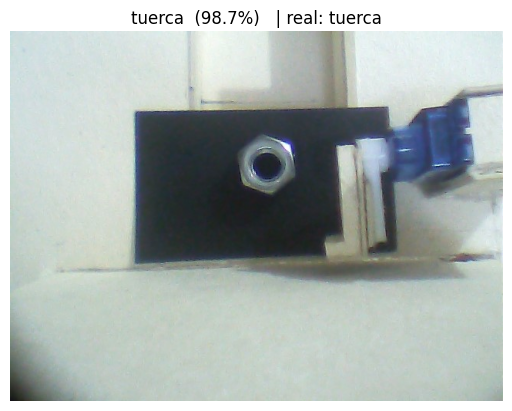

In [33]:
# Prueba de UNA imagen con el mismo preprocesamiento que usará la Raspberry (OpenCV carga en BGR -> convertir a RGB)
ruta = test.filepaths[0]
bgr = cv2.imread(ruta)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
x = cv2.resize(rgb, (WIDTH, HEIGHT)).astype(np.float32) / 255.0
x = np.expand_dims(x, 0)

interp.set_tensor(ent["index"], x)
interp.invoke()
p = interp.get_tensor(sal["index"])[0]
i = int(np.argmax(p))
plt.imshow(rgb); plt.axis("off")
plt.title(f"{orden[i]}  ({p[i]*100:.1f}%)   | real: {CLASES[test.classes[0]]}")
plt.show()

## 11. Descargar los archivos

In [34]:
salidas = [f"{NOMBRE_MODELO}.tflite", f"{NOMBRE_MODELO}.h5", "config_clases.json", "labels.txt",
           "curvas_entrenamiento.png", "matriz_confusion.png", "reporte_clasificacion.txt"]
salidas += [f for f in ["curvas_fine_tuning.png", "errores_test.png"] if os.path.exists(f)]

with zipfile.ZipFile("salidas_miniproyecto3.zip", "w") as z:
    for f in salidas:
        z.write(f)
files.download("salidas_miniproyecto3.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>